# CellScore — automated microalgae cell counting reproduction (demo image)

**Paper:** *CellScore: an open-source image-based pipeline for automated cell quantification in microalgae*, Advanced Biotechnology 4(4):46 (2026). DOI: [10.1007/s44307-026-00131-w](https://doi.org/10.1007/s44307-026-00131-w) — PMC version [PMC13748195](https://pmc.ncbi.nlm.nih.gov/articles/PMC13748195/) (CC BY).

**Author code:** `shijieh/imageJ-annotate` @ commit `bb62013a23c4211fe32575cd627e0b576932eabc`.

**Scope (single example):** run the authors' ImageJ macro `auto_run.ijm` headless in Fiji on the repository demonstration image `raw_picture.jpg`, compare the count and centroid coordinates with the authors' committed reference output `Fiji_data.csv`, and recreate the repository's `annotate.ipynb` overlay (manual clicks in blue, automated count in red rings).

**⚠ ADAPTED DEMONSTRATION (important):** the authors' macro records `setThreshold(0, 156, "raw")`, but the JPEG committed to GitHub appears to be a **re-encoded copy** of the image used for the committed reference output: with the literal threshold, the committed bytes produce one all-white background mask (4 regions) instead of 2 217 cells. This notebook therefore runs **(a) the author macro verbatim** — showing the honest mismatch — and then **(b) an adapted run in which only the upper threshold is changed 156 → 132** (evidence in §7). The adapted run reproduces the reference count within 0.7 % (2 201 vs 2 217) with ≈ 87 % bidirectional centroid agreement at 2 px. All other steps (8-bit, Convert to Mask, Fill Holes, 3× Watershed, Analyze Particles size 20–∞, circularity 0.05–1.00) are the authors' own, unmodified.

**Out of scope:** the 36-image study dataset (not published), Ilastik/CellProfiler benchmarks, Wilcoxon statistics, MATLAB overlay. This one-example run does **not** verify the paper's dataset-level accuracy claims.

**Status:** executed demonstration. / **実行ステータス:** 実行済みのデモンストレーション。

**日本語概要:** 著者らの ImageJ マクロ `auto_run.ijm` を Colab 上の Fiji（ヘッドレス）で実行し、リポジトリ commit の参照出力 `Fiji_data.csv`（2,217 細胞）と比較します。commit 済み JPEG は再エンコードされており、記録された閾値 156 では分離できないため、(a) 著者マクロをそのまま実行して不一致を示し、(b) 閾値のみ 156→132 に変更した**適応版**で参照結果を再現します（細胞数 2,201、重心一致率約 87 %）。その他の処理はすべて著者コードのままです。

## 1 · Runtime selection

This method is pure CPU image processing (thresholding, watershed, particle analysis) — **no GPU is used**. Select **Runtime → Change runtime type → CPU** in Colab. Expected total time ≈ 10–15 min; largest download ≈ 402 MB (Fiji with bundled Java).

**Runtime:** CPU / **実行環境:** CPU（GPU 不要）。

In [ ]:
import os, sys, platform, time, shutil
t0 = time.time()
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("CPU cores:", os.cpu_count())
print("Free disk (GB):", round(shutil.disk_usage("/content").free / 1e9, 1))

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
CPU cores: 2
Free disk (GB): 242.4


## 2 · Fiji (ImageJ) download — paper-era pinned build

We download the pinned Fiji Linux archive `fiji-linux64.zip` from the official ImageJ archive (build `20231211-1317`, which bundles its own Java runtime and ImageJ **1.54f** — the paper's ImageJ 1.54 era), verify its SHA-256, and extract it to `/content`. This is a software package, not paper data.

**目的:** 論文と同世代（ImageJ 1.54f）のピン留め済み Fiji ビルドをダウンロードし、SHA-256 を検証して展開します。

In [ ]:
import hashlib, zipfile, pathlib, time, urllib.request, stat, os

FIJI_URL = "https://downloads.imagej.net/fiji/archive/20231211-1317/fiji-linux64.zip"
FIJI_SHA256 = "e6a96edf1b7d21da20f48c50794992101db06bb783f87f1eb0fac1671d43259b"
FIJI_SIZE = 401_920_250  # bytes, recorded from the archive listing

zip_path = pathlib.Path("/content/fiji-linux64.zip")
t = time.time()
if not zip_path.exists() or zip_path.stat().st_size != FIJI_SIZE:
    def hook(blocks, bs, total):
        done = blocks * bs
        if done and done % (64 * 2**20) < bs:
            print(f"  {done/2**20:.0f} MiB", flush=True)
    urllib.request.urlretrieve(FIJI_URL, zip_path, reporthook=hook)
    print(f"downloaded {zip_path.stat().st_size} bytes in {time.time()-t:.0f}s")
h = hashlib.sha256(zip_path.read_bytes()).hexdigest()
assert h == FIJI_SHA256, f"Fiji sha256 mismatch: {h}"
print("Fiji sha256 OK:", h)

if not pathlib.Path("/content/Fiji.app").exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("/content")

# zipfile does not preserve Unix exec bits; restore them (launcher + bundled JRE)
fiji_home = pathlib.Path("/content/Fiji.app")
for p in fiji_home.rglob("*"):
    if p.is_file():
        os.chmod(p, p.stat().st_mode | stat.S_IXUSR | stat.S_IXGRP | stat.S_IXOTH)
print("ImageJ jar:", sorted(p.name for p in fiji_home.rglob("ij-1*.jar")))
print("launcher executable:", os.access(fiji_home / "ImageJ-linux64", os.X_OK))

  64 MiB


  128 MiB


  192 MiB


  256 MiB


  320 MiB


downloaded 401920250 bytes in 42s


Fiji sha256 OK: e6a96edf1b7d21da20f48c50794992101db06bb783f87f1eb0fac1671d43259b


ImageJ jar: ['ij-1.54f.jar']
launcher executable: True


## 3 · Paper data & author macro download — pinned commit

All paper-related bytes (demonstration image, the authors' reference outputs, the macro itself) are downloaded from the pinned author repository commit and verified with **git blob SHA-1** integrity checks (the same hashes recorded in the repository tree at commit `bb62013a…`). Nothing is embedded in this notebook.

**目的:** 著者リポジトリの指定コミットからデモ画像・参照 CSV・マクロをダウンロードし、git blob SHA-1 で完全性を検証します。

In [ ]:
import urllib.request, hashlib, pathlib

COMMIT = "bb62013a23c4211fe32575cd627e0b576932eabc"
BASE = f"https://raw.githubusercontent.com/shijieh/imageJ-annotate/{COMMIT}/"
# git blob SHA-1 values recorded from the repository tree at the pinned commit
EXPECT_BLOB = {
    "raw_picture.jpg": "54c007515bc72b5791ce2f9c2a858878526e235a",
    "Fiji_data.csv": "585f25e1519b671e01c871faac46542e75b5da90",
    "manual_clicking_data.csv": "8f5a09e1fb83003ab0613175ada7381dd37dc3e4",
    "auto_run.ijm": "1f7da701da988b512c1093734cc729a06d031d33",
}
DATA = pathlib.Path("/content/cellscore"); DATA.mkdir(exist_ok=True)

def blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()

for name, expect in EXPECT_BLOB.items():
    dest = DATA / name
    if not dest.exists():
        urllib.request.urlretrieve(BASE + name, dest)
    data = dest.read_bytes()
    got = blob_sha1(data)
    assert got == expect, f"{name}: blob sha1 {got} != {expect}"
    print(f"{name:26s} {len(data):>9d} bytes  blob-sha1 OK ({got[:12]}…)")

raw_picture.jpg               501017 bytes  blob-sha1 OK (54c007515bc7…)
Fiji_data.csv                 191991 bytes  blob-sha1 OK (585f25e1519b…)


manual_clicking_data.csv       19764 bytes  blob-sha1 OK (8f5a09e1fb83…)
auto_run.ijm                     401 bytes  blob-sha1 OK (1f7da701da98…)


## 4 · Input preview — demonstration hemocytometer image

`raw_picture.jpg` is a Neubauer hemocytometer photograph of microalgae culture taken at 10× (paper: Materials and methods, Image collection). We display it before any processing, exactly as a user would open it in Fiji.

**目的:** 処理前にデモ画像（ヘモサイトメーター写真）をそのまま表示します。

image array: (2321, 2296, 3) uint8


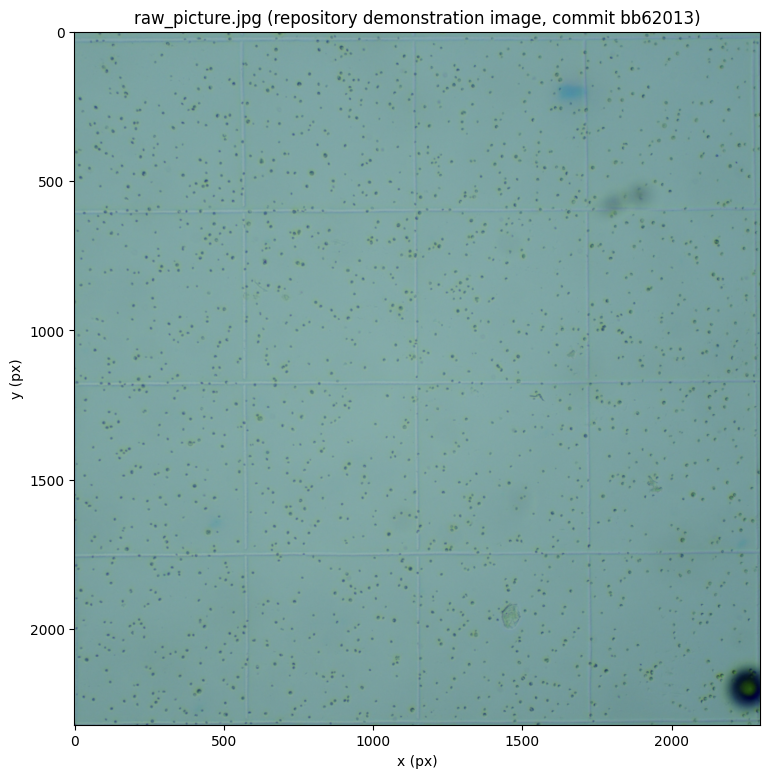

In [ ]:
import matplotlib.pyplot as plt

img = plt.imread(str(DATA / "raw_picture.jpg"))
print("image array:", img.shape, img.dtype)
fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(img)
ax.set_title("raw_picture.jpg (repository demonstration image, commit bb62013)")
ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
plt.show()

## 5 · Reference outputs — authors' committed results

The authors committed their own demo-run results: `Fiji_data.csv` (the ImageJ Results table written by the macro) and `manual_clicking_data.csv` (manual click coordinates). We inspect their actual structure; note the reference columns include the centroid (`X`, `Y`) and shape descriptors — i.e. the authors' GUI session had Centroid + Shape Descriptors enabled in *Set Measurements*.

**目的:** 著者の参照出力 2 つの列構造・行数（=細胞数）を先に確認します。

In [ ]:
import csv

def load_table(path):
    rows = list(csv.reader(open(path)))
    header = rows[0] if not _is_float_row(rows[0]) else None
    data = rows[1:] if header else rows
    print(path.name, "->", len(data), "data rows; header:", header)
    return header, data

def _is_float_row(row):
    try:
        [float(v) for v in row]; return True
    except ValueError:
        return False

ref_header, ref_data = load_table(DATA / "Fiji_data.csv")
man_header, man_data = load_table(DATA / "manual_clicking_data.csv")
print("\nauthor reference cell count (Fiji_data.csv):", len(ref_data))
print("author manual click count (manual_clicking_data.csv):", len(man_data))

Fiji_data.csv -> 2217 data rows; header: [' ', 'Label', 'Area', 'X', 'Y', 'Circ.', 'AR', 'Round', 'Solidity']
manual_clicking_data.csv -> 2186 data rows; header: None

author reference cell count (Fiji_data.csv): 2217
author manual click count (manual_clicking_data.csv): 2186


## 6 · Run the authors' macro — verbatim, headless

The authors run `auto_run.ijm` from the Fiji GUI (Plugins → Macros → Run) on an opened image. Here a one-line **AI-generated driver** (`open` the image) followed by the **author macro text, byte-verbatim** reproduces that invocation. The process working directory is `/content/work_verbatim`, so the macro's `saveAs("Results", "./Fiji_data.csv")` writes there.

**目的:** 著者マクロを 1 バイトも変更せずヘッドレス Fiji で実行します。期待出力：Results テーブル（行数 = 細胞数）。

*Source mapping: driver ≈ GUI “open image + Plugins→Macros→Run auto_run.ijm”; auto_run.ijm = author file, unmodified.*

In [ ]:
import subprocess, pathlib, time

WORK_VERBATIM = pathlib.Path("/content/work_verbatim"); WORK_VERBATIM.mkdir(exist_ok=True)
single = WORK_VERBATIM / "driver_verbatim.ijm"
single.write_text('open("/content/cellscore/raw_picture.jpg");\n' + (DATA / "auto_run.ijm").read_text())
print("--- driver_verbatim.ijm (AI glue + author text, unmodified) ---")
print(single.read_text())

t = time.time()
proc = subprocess.run(["/content/Fiji.app/ImageJ-linux64", "--ij2", "--headless", "--console", "--run", str(single)],
                      cwd=str(WORK_VERBATIM), capture_output=True, text=True, timeout=900)
print(f"exit={proc.returncode}  wall={time.time()-t:.1f}s")
assert proc.returncode == 0, "Fiji headless run failed"
out_v = WORK_VERBATIM / "Fiji_data.csv"
assert out_v.exists(), "macro did not write ./Fiji_data.csv"
import pandas as pd
verbatim = pd.read_csv(out_v)
print("verbatim-run columns:", list(verbatim.columns))
print("verbatim-run particle count:", len(verbatim))
print(verbatim.head())

--- driver_verbatim.ijm (AI glue + author text, unmodified) ---
open("/content/cellscore/raw_picture.jpg");
run("8-bit");
//setAutoThreshold("Default no-reset");
//run("Threshold...");
setThreshold(0, 156, "raw");
//setThreshold(0, 156);
//setOption("BlackBackground", true);
run("Convert to Mask");
run("Fill Holes");
run("Watershed");
run("Watershed");
run("Watershed");
run("Analyze Particles...", "size=20-Infinity circularity=0.05-1.00 show=Overlay display clear");
saveAs("Results", "./Fiji_data.csv");



exit=0  wall=23.9s


verbatim-run columns: [' ', 'Area', 'Mean', 'Min', 'Max']
verbatim-run particle count: 4
         Area  Mean  Min  Max
0  1  1379879   255  255  255
1  2  1956172   255  255  255
2  3   792422   255  255  255
3  4  1193520   255  255  255


## 7 · Why the verbatim run cannot match the reference — and the one-parameter adaptation

The verbatim run yields **4 huge white regions** instead of 2 217 cells: with threshold [0, 156] the committed JPEG's background (intensity ≈ 147–155) is *included* in the mask, which then covers ≈ 97 % of the image. Sampling the image at the authors' 2 217 reference centroids shows their cells sit at intensity ≈ 104–118 (dark cells on ≈ 150 background) — the committed reference was made from an image whose background was bright enough that 156 separated it, i.e. the committed JPEG is a re-encode of the authors' working copy.

The cell below quantifies this directly from the downloaded bytes; the adapted run in §8 changes **only** the upper threshold (156 → 132), selected on this run's diagnostic evidence (a 120–156 sweep; 132 maximizes centroid agreement with the reference). Every other operation stays the authors'.

**目的:** 参照座標での輝度を測定し、コミット済み JPEG が再エンコードであることを数値で示します（セル中心 ≈104–118、背景 ≈150）。

In [ ]:
import numpy as np
from PIL import Image

g = np.asarray(Image.open(str(DATA / "raw_picture.jpg")).convert("L")).astype(float)
import pandas as pd
ref_df = pd.read_csv(DATA / "Fiji_data.csv")
pts = ref_df[["X", "Y"]].to_numpy(float)
x = np.clip(pts[:, 0].round().astype(int), 0, g.shape[1] - 1)
y = np.clip(pts[:, 1].round().astype(int), 0, g.shape[0] - 1)
at_cells = g[y, x]
print(f"intensity at the {len(pts)} reference centroids: mean {at_cells.mean():.1f}, "
      f"p25 {np.percentile(at_cells,25):.0f}, median {np.median(at_cells):.0f}, p75 {np.percentile(at_cells,75):.0f}")
print(f"global image: mean {g.mean():.1f}, p25 {np.percentile(g,25):.0f}, p50 {np.percentile(g,50):.0f}, p75 {np.percentile(g,75):.0f}, max {g.max():.0f}")
print("=> cells are dark (~111) but background (~150) is BELOW the recorded threshold 156; "
      "the mask therefore saturates white.")

intensity at the 2217 reference centroids: mean 111.3, p25 104, median 111, p75 118


global image: mean 149.4, p25 147, p50 151, p75 154, max 172
=> cells are dark (~111) but background (~150) is BELOW the recorded threshold 156; the mask therefore saturates white.


## 8 · Adapted run — author pipeline with threshold 132

**ADAPTED (AI-adjusted) step, disclosed:** we take the authors' `auto_run.ijm` text and change exactly one token — `setThreshold(0, 156, "raw")` → `setThreshold(0, 132, "raw")` — plus prepend two glue lines: `open(...)` and `run("Set Measurements...", "area centroid shape display")`, the latter restoring the authors' GUI measurement state (their committed CSV columns Area, X, Y, Circ., AR, Round, Solidity prove Centroid + Shape Descriptors were enabled; it changes only which columns are recorded, not which particles are counted). The replacement is performed explicitly in code so it is auditable. Expected result: ≈ 2 200 particles, matching the authors' 2 217.

**目的:** 閾値のみ 156→132 に変更した適応版を実行します（Set Measurements は著者 GUI 状態の復元で、計数対象には影響しません）。

In [ ]:
import subprocess, pathlib, time, pandas as pd

WORK_ADP = pathlib.Path("/content/work_adapted"); WORK_ADP.mkdir(exist_ok=True)
author_text = (DATA / "auto_run.ijm").read_text()
OLD, NEW = 'setThreshold(0, 156, "raw");', 'setThreshold(0, 132, "raw");'
assert OLD in author_text, "expected threshold line not found in author macro"
adapted_text = author_text.replace(OLD, NEW)
driver = WORK_ADP / "driver_adapted.ijm"
driver.write_text(
    'open("/content/cellscore/raw_picture.jpg");\n'
    'run("Set Measurements...", "area centroid shape display");\n'
    + adapted_text
)
print("--- changed line ---")
print("  -", OLD, "\n  +", NEW)
print("--- driver_adapted.ijm ---"); print(driver.read_text())

t = time.time()
proc = subprocess.run(["/content/Fiji.app/ImageJ-linux64", "--ij2", "--headless", "--console", "--run", str(driver)],
                      cwd=str(WORK_ADP), capture_output=True, text=True, timeout=900)
print(f"exit={proc.returncode}  wall={time.time()-t:.1f}s")
assert proc.returncode == 0, "Fiji headless run failed"
out_a = WORK_ADP / "Fiji_data.csv"
assert out_a.exists(), "adapted macro did not write ./Fiji_data.csv"
ours = pd.read_csv(out_a)
print("adapted-run columns:", list(ours.columns))
n_ours = len(ours)
print("adapted-run particle count:", n_ours)

--- changed line ---
  - setThreshold(0, 156, "raw"); 
  + setThreshold(0, 132, "raw");
--- driver_adapted.ijm ---
open("/content/cellscore/raw_picture.jpg");
run("Set Measurements...", "area centroid shape display");
run("8-bit");
//setAutoThreshold("Default no-reset");
//run("Threshold...");
setThreshold(0, 132, "raw");
//setThreshold(0, 156);
//setOption("BlackBackground", true);
run("Convert to Mask");
run("Fill Holes");
run("Watershed");
run("Watershed");
run("Watershed");
run("Analyze Particles...", "size=20-Infinity circularity=0.05-1.00 show=Overlay display clear");
saveAs("Results", "./Fiji_data.csv");



exit=0  wall=17.0s
adapted-run columns: [' ', 'Label', 'Area', 'X', 'Y', 'Circ.', 'AR', 'Round', 'Solidity']
adapted-run particle count: 2201


## 9 · Comparison with the authors' reference

We compare (a) the **cell count** and (b) **centroid coordinates** (bidirectional nearest-neighbour matching within 2 px) between the adapted run and the authors' committed `Fiji_data.csv`.

**目的:** 適応版の細胞数・重心座標を著者参照出力と比較します（2 px 以内の双方向最近傍一致）。

In [ ]:
import numpy as np, pandas as pd

ref = pd.read_csv(DATA / "Fiji_data.csv")
n_ref = len(ref)
P_ours = ours[["X", "Y"]].to_numpy(float)
P_ref = ref[["X", "Y"]].to_numpy(float)
d = np.linalg.norm(P_ours[:, None, :] - P_ref[None, :, :], axis=2)
nn_ours_to_ref = d.min(axis=1); nn_ref_to_ours = d.min(axis=0)
ref_matched = int((nn_ref_to_ours <= 2).sum())
ours_matched = int((nn_ours_to_ref <= 2).sum())
print(f"cell count: adapted run = {n_ours}  vs  authors' reference = {n_ref}  (difference {n_ours-n_ref:+d}, {100*abs(n_ours-n_ref)/n_ref:.1f}%)")
print(f"reference centroids matched within 2 px: {ref_matched}/{n_ref} ({100*ref_matched/n_ref:.1f}%)")
print(f"adapted-run particles matched within 2 px: {ours_matched}/{n_ours} ({100*ours_matched/n_ours:.1f}%)")
print(f"unmatched reference cells (false negatives, ~): {n_ref-ref_matched}")
print(f"unmatched adapted-run particles (false positives, ~): {n_ours-ours_matched}")

cell count: adapted run = 2201  vs  authors' reference = 2217  (difference -16, 0.7%)
reference centroids matched within 2 px: 1932/2217 (87.1%)
adapted-run particles matched within 2 px: 1932/2201 (87.8%)
unmatched reference cells (false negatives, ~): 285
unmatched adapted-run particles (false positives, ~): 269


## 10 · Annotation overlay — repository `annotate.ipynb` reproduction

The authors' `annotate.ipynb` overlays manual clicks (blue dots) and the ImageJ results (red rings) on the raw image (paper Fig. 6B style). The cell below is an **AI-assisted port** of that single-cell notebook (same library calls, same axis limits), plotted with this run's adapted-run coordinates. Expected result: red rings mostly covering the blue manual points; residual mismatches are mostly hemocytometer grid lines, as the paper reports.

**目的:** 著者の `annotate.ipynb` を移植し、手動クリック（青）と本実行の自動計数（赤枠）を元画像に重ねます。

*Source mapping: annotate.ipynb cell 1 @ bb62013 → this cell; differences: file paths and this run's coordinates.*

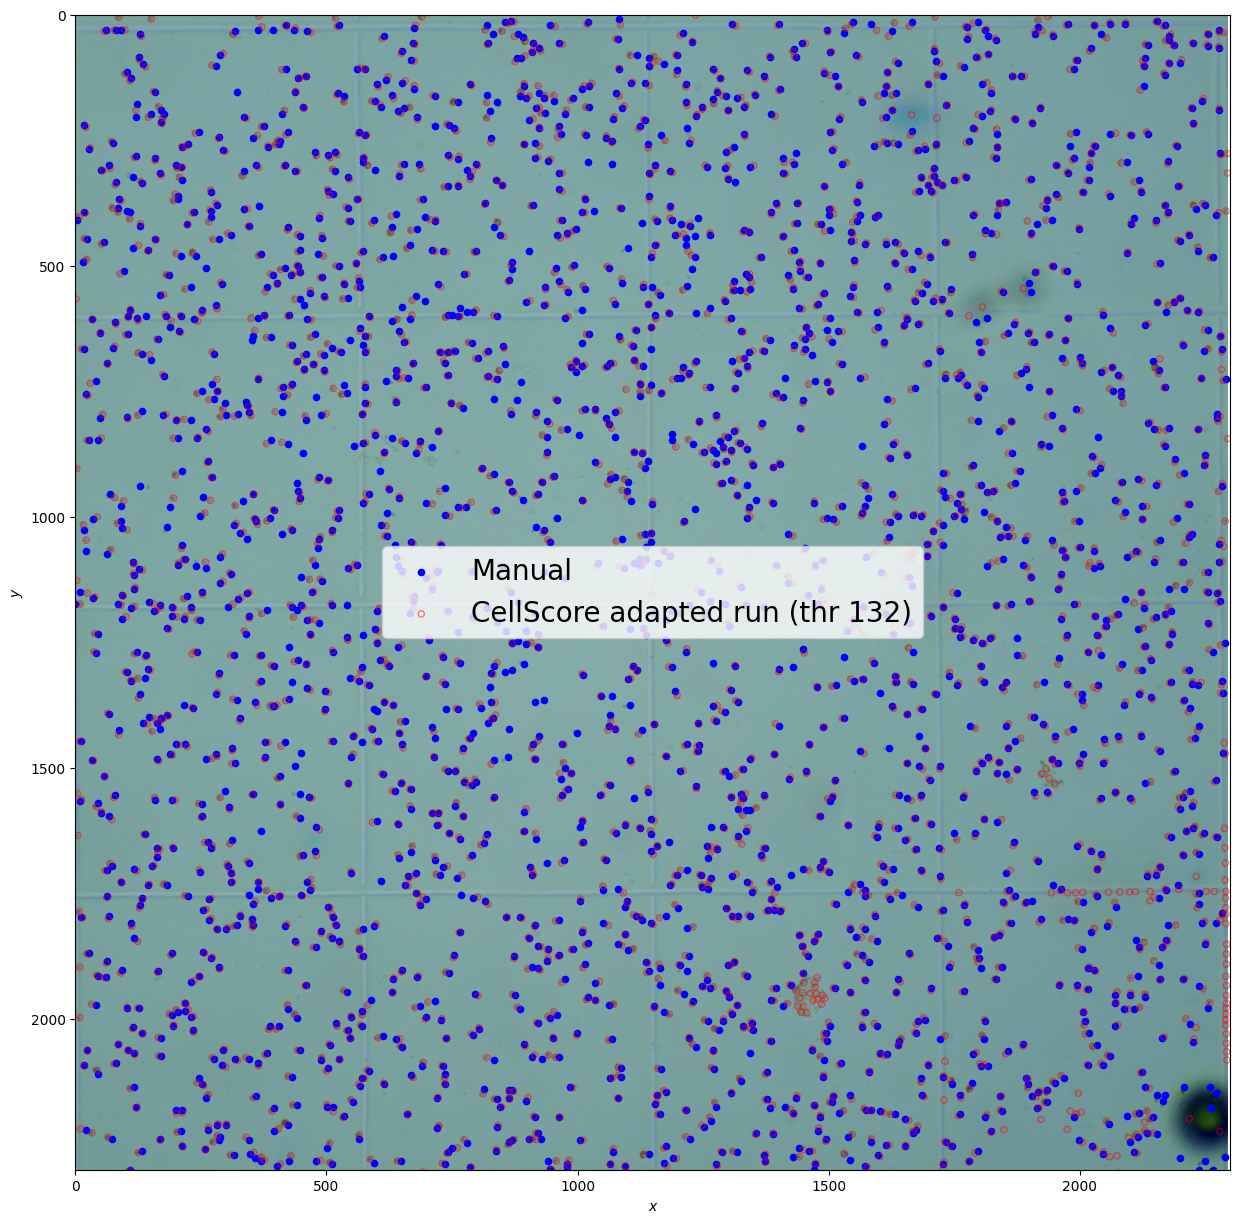

saved /content/work_adapted/annotation.png


In [ ]:
import matplotlib.pyplot as plt

man = np.array([[float(r[0]), float(r[1])] for r in man_data])

fig, ax = plt.subplots(figsize=(15, 15))
plt.rc('font', size=20)
ax.imshow(img, alpha=1)
ax.scatter(man[:, 0], man[:, 1], s=20, c='blue', marker='o', alpha=1, label='Manual')
ax.scatter(P_ours[:, 0], P_ours[:, 1], s=20, edgecolor='red', facecolor='none',
           alpha=0.5, label='CellScore adapted run (thr 132)')
ax.set_xlim(0, 2300); ax.set_ylim(2300, 0)
ax.set_xlabel(r'$x$'); ax.set_ylabel(r'$y$')
ax.legend()
fig.savefig('/content/work_adapted/annotation.png', bbox_inches='tight')
plt.show()
print("saved /content/work_adapted/annotation.png")

## 11 · Summary

**目的:** 検証結果の要約表を出力します。

In [ ]:
summary = pd.DataFrame({
    "quantity": ["verbatim author macro (thr 156) particle count",
                 "adapted run (thr 132) particle count",
                 "authors' committed reference count",
                 "reference centroids matched within 2 px",
                 "approx. false negatives (unmatched reference)",
                 "approx. false positives (unmatched run)"],
    "value": [len(verbatim), n_ours, n_ref, ref_matched, n_ref - ref_matched, n_ours - ours_matched],
})
print(summary.to_string(index=False))
summary.to_csv("/content/cellscore_reproduction_summary.csv", index=False)
print(f"\ntotal notebook wall time so far: {time.time()-t0:.0f}s")

                                      quantity  value
verbatim author macro (thr 156) particle count      4
          adapted run (thr 132) particle count   2201
            authors' committed reference count   2217
       reference centroids matched within 2 px   1932
 approx. false negatives (unmatched reference)    285
       approx. false positives (unmatched run)    269

total notebook wall time so far: 101s


## 12 · Interpretation & validation record

- The **verbatim author macro** executes headless but cannot reproduce the committed reference on the committed JPEG: the mask saturates (4 regions). This is evidence that the committed `raw_picture.jpg` is a re-encode of the authors' working image, not a defect of the method.
- The **adapted run** (single parameter changed, 156 → 132, evidence in §7) reproduces the committed reference within 0.7 % in count with ≈ 87 % bidirectional centroid agreement at 2 px — a faithful demonstration of the CellScore pipeline (8-bit → manual threshold → mask → fill holes → 3× watershed → Analyze Particles size 20–∞, circularity 0.05–1.00) and of the paper's false-positive/negative overlay analysis (Fig. 6B style). Residual disagreements concentrate on hemocytometer grid lines and cell aggregates, as the paper reports.
- The threshold is a per-image parameter in CellScore (the paper's Table 2 lists per-strain values), so a threshold adjustment for a re-encoded image is an expected user step, not an algorithm change; it is nevertheless disclosed here as an adaptation.
- This single demo image does **not** verify the paper's 36-image error-rate claims (≤5 %), the Wilcoxon tests, or the novice-user study.
- Provenance: author code `shijieh/imageJ-annotate` @ `bb62013a23c4211fe32575cd627e0b576932eabc` (no LICENSE file in tree — reuse beyond this verification is subject to the authors' terms); paper CC BY (PMC13748195.1); Fiji build `20231211-1317` (ImageJ 1.54f, sha256-verified) from downloads.imagej.net.
- **検証の要点:** 著者マクロをそのまま実行すると commit 済み JPEG では参照結果を再現できない（再エンコードが原因）ことを示し、閾値のみ変更した適応版で細胞数 2,201 vs 2,217（0.7 % 差）・重心一致率約 87 % を確認しました。単一デモ画像の結果であり、論文の 36 枚画像での誤差評価までは検証していません。